# 02 · Pair evidence: what does the data actually support?

The obvious hackathon answer is a market-basket recommender: "people who buy X also buy Y". Before building one we
test whether specific pairs exist, at three levels:

1. **Product pairs** (classic market basket, every drink x food combination).
2. **Category pairs** (drink category x food category).
3. **Products within categories**: once you know the categories, does the specific drink predict the specific food?

Then we check **customer IDs** (do individual customers have personal favourites?) and run a **held-out
benchmark**: which method best predicts the item actually added in June?

**What we find**
- **The classic market-basket view finds nothing**: across all orders no product pair is significant, and even every
  *category* pair has lift at or below 1. That is not because pairs don't exist; it is because 72% of orders are
  single-sided, so drinks and food rarely share a receipt at all. Lift over all orders is the wrong tool here.
- **Among orders that do pair, category pairs are strong**: cold drinks with sandwiches (lift 1.8) and meals (1.7),
  matcha/tea with bakery (1.2), all with q < 0.001.
- Some product pairs also look significant there, but every one sits inside a significant category pair (cold drinks x
  sandwiches/meals). **Inside a category, the specific product chosen does not depend on the drink** (0 of 20 tests
  survive correction).
- The add-on depends more strongly on the *first* line of an order than in the pooled view, supporting the use of the
  first line as the anchor item.
- **Customer IDs do not carry personal preferences**: a returning customer repeats their previous choice no more
  often than chance (z = -0.85 for food), and 94% of IDs appear at more than one branch.
- On June orders, product association rules are no better than plain popularity. The category-aware predictor gives
  the best probabilities (lowest log loss); top-3 hit rates are within noise of popularity.

**Decision:** the engine picks the category from data and the product by profit. We **reject** a product-level
market-basket recommender and customer-level personalisation for this data.

In [1]:
# Setup: works in Google Colab, local Jupyter, and from the repo root
import os, sys, subprocess
REPO_URL = "https://github.com/mouhammed-soumaille/EECE-490-Hackathon.git"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/EECE-490-Hackathon"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/EECE-490-Hackathon"], check=True)
    os.chdir("/content/EECE-490-Hackathon")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from storiespair import data, evidence, viz
viz.style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

lines = data.load_lines()
orders = data.build_orders(lines)

## 1. Classic market basket over all orders

In [2]:
prod = evidence.pair_table(lines, "product")
cat_all = evidence.pair_table(lines, "category")
print(f"{len(prod)} drink x food product pairs tested across {orders.shape[0]:,} orders")
print(f"Product pairs with lift > 1 and BH q < 0.05: {int(((prod.lift > 1) & (prod.q_value < 0.05)).sum())} (max lift {prod.lift.max():.2f})")
print(f"Category pairs with lift > 1: {int((cat_all.lift > 1).sum())} of {len(cat_all)} (max lift {cat_all.lift.max():.2f})")
prod.head(8)[["drink", "food", "n_both", "confidence", "lift", "p_value", "q_value"]].round(4)

506 drink x food product pairs tested across 33,887 orders
Product pairs with lift > 1 and BH q < 0.05: 0 (max lift 1.36)
Category pairs with lift > 1: 0 of 20 (max lift 1.00)


,drink,food,n_both,confidence,lift,p_value,q_value
0,Sparkling Water,Chicken Salad Bowl,21,0.0207,1.3640,0.0956,1.0
1,Fresh Orange Juice,Tuna Sandwich,24,0.0253,1.2584,0.1495,1.0
2,Sparkling Water,Turkey & Cheese Sandwich,37,0.0365,1.2341,0.1121,1.0
3,Peach Iced Tea,Quinoa Bowl,19,0.0169,1.2147,0.2241,1.0
4,Fresh Orange Juice,Quinoa Bowl,16,0.0169,1.2104,0.2525,1.0
5,English Breakfast Tea,Chocolate Cookie,25,0.0558,1.1946,0.2069,1.0
6,Espresso,Soup of the Day,9,0.0139,1.1187,0.4138,1.0
7,Mint Tea,Chocolate Cookie,31,0.0520,1.1134,0.2941,1.0


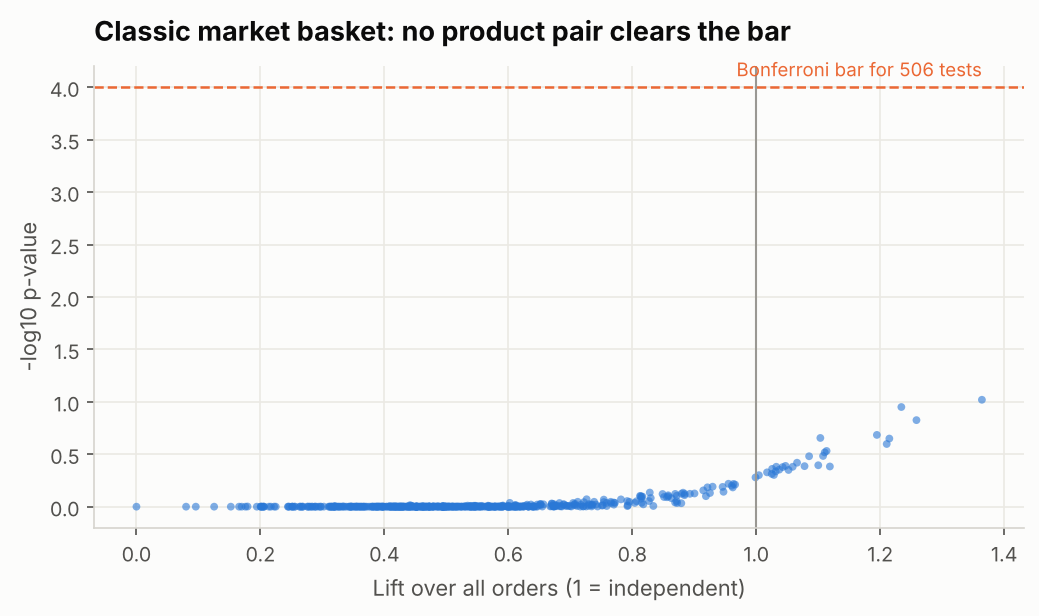

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(prod.lift, -np.log10(prod.p_value), s=14, color=viz.BLUE, alpha=0.6, edgecolor="none")
bonf = 0.05 / len(prod)
ax.axhline(-np.log10(bonf), color=viz.ORANGE, ls="--", lw=1.2)
ax.text(prod.lift.max(), -np.log10(bonf) + 0.1, f"Bonferroni bar for {len(prod)} tests", ha="right", color=viz.ORANGE, fontsize=9)
ax.axvline(1, color=viz.GREY, lw=1)
ax.set_xlabel("Lift over all orders (1 = independent)")
ax.set_ylabel("-log10 p-value")
ax.set_title("Classic market basket: no product pair clears the bar")
viz.savefig(fig, "02_product_pairs_volcano")
plt.show()

With 72% of orders single-sided, a drink and a food share a receipt less often than independence would predict, so
almost every lift is below 1. A team that stops here concludes "there are no pairs". The right question is
conditional: **when an order does pair, which combinations are over-represented?**

## 2. Among orders that pair

In [4]:
mixed_ids = orders.loc[orders.composition == "drink + food", "transaction_id"]
lm = lines[lines.transaction_id.isin(mixed_ids)]
cat = evidence.pair_table(lm, "category")
cat["significant"] = (cat.q_value < 0.05) & (cat.lift > 1)
print(f"{len(mixed_ids):,} orders with both a drink and a food")
cat[["drink", "food", "n_both", "confidence", "lift", "q_value", "significant"]].round(4).head(10)

9,563 orders with both a drink and a food


,drink,food,n_both,confidence,lift,q_value,significant
0,Cold Drinks,Sandwiches,532,0.3063,1.8215,0.0000,True
1,Cold Drinks,Meals,192,0.1105,1.6886,0.0000,True
2,Matcha & Tea,Bakery,1994,0.6574,1.2042,0.0000,True
3,Cold Drinks,Breakfast,188,0.1082,1.1883,0.0159,True
4,Cold Coffee,Desserts,468,0.1886,1.1289,0.0026,True
5,Hot Coffee,Breakfast,281,0.0990,1.0875,0.1448,False
6,Cold Coffee,Breakfast,242,0.0975,1.0709,0.2613,False
7,Cold Drinks,Desserts,307,0.1767,1.0577,0.2765,False
8,Hot Coffee,Bakery,1580,0.5569,1.0201,0.2408,False
9,Cold Coffee,Meals,165,0.0665,1.0160,0.8386,False


In [5]:
prod_m = evidence.pair_table(lm, "product")
sig = prod_m[(prod_m.q_value < 0.05) & (prod_m.lift > 1)]
cat_of = lines.drop_duplicates("product").set_index("product").category
sig = sig.assign(drink_cat=sig.drink.map(cat_of), food_cat=sig.food.map(cat_of))
print(f"Significant product pairs among paired orders: {len(sig)}; their category pairs:")
print(sig.groupby(["drink_cat", "food_cat"]).size().to_string())
sig[["drink", "food", "n_both", "lift", "q_value"]].round(4).head(8)

Significant product pairs among paired orders: 13; their category pairs:
drink_cat     food_cat  
Cold Drinks   Meals         2
              Sandwiches    9
Matcha & Tea  Bakery        2


,drink,food,n_both,lift,q_value
0,Sparkling Water,Chicken Salad Bowl,21,2.5388,0.0081
1,Sparkling Water,Turkey & Cheese Sandwich,37,2.2976,0.0009
2,Fresh Orange Juice,Tuna Sandwich,24,2.2942,0.0091
3,Peach Iced Tea,Quinoa Bowl,19,2.2042,0.0397
7,Peach Iced Tea,Tuna Sandwich,25,2.1015,0.0158
8,Peach Iced Tea,Turkey & Cheese Sandwich,36,2.0977,0.0032
9,Peach Iced Tea,Chicken Pesto Sandwich,38,2.0467,0.0032
11,Sparkling Water,Halloumi Wrap,30,2.0289,0.0109


Every significant product pair sits inside an already-significant category pair. The next section tests whether the
product adds anything once the category is known.

## 3. Is there anything below the category?

In [6]:
pairs = evidence.paired_orders(lines)
tests = evidence.conditional_tests(pairs)
tests[["level", "test", "n", "chi2", "dof", "p_value", "p_bonferroni", "cramers_v", "significant_5pct"]].round(4)

,level,test,n,chi2,dof,p_value,p_bonferroni,cramers_v,significant_5pct
0,category / context,Drink category -> food category,9563,656.4,12,0.0000,0.0000,0.151,True
1,category / context,Daypart -> food category,9563,202.5,12,0.0000,0.0000,0.084,True
2,category / context,Branch -> food category,9563,92.1,8,0.0000,0.0000,0.069,True
3,category / context,Order type -> food category,9563,20.1,4,0.0005,0.0024,0.046,True
4,category / context,Daypart -> drink category,9563,301.0,9,0.0000,0.0000,0.102,True
5,product (within category),Within Cold Coffee: drink product -> food cate...,2326,13.3,16,0.6486,1.0000,0.038,False
6,product (within category),Within Cold Drinks: drink product -> food cate...,1625,19.8,16,0.2314,1.0000,0.055,False
7,product (within category),Within Hot Coffee: drink product -> food category,2693,27.5,24,0.2798,1.0000,0.051,False
8,product (within category),Within Matcha & Tea: drink product -> food cat...,2919,22.7,20,0.3018,1.0000,0.044,False
9,product (within category),Within Bakery: drink category -> food product,5100,26.2,21,0.1987,1.0000,0.041,False


In [7]:
fam = tests[tests.level != "category / context"]
print(f"Product-level tests (within categories): {len(fam)}; significant after Bonferroni: {int(fam.significant_5pct.sum())}")
print(f"Smallest raw p-value in the family: {fam.p_value.min():.4f} (Bonferroni threshold 0.05/{len(fam)} = {0.05/len(fam):.4f})")

Product-level tests (within categories): 20; significant after Bonferroni: 0
Smallest raw p-value in the family: 0.0080 (Bonferroni threshold 0.05/20 = 0.0025)


Every category/context test is significant; none of the product-within-category tests is. Once you know a customer
bought a Hot Coffee and is adding Bakery, whether it was a Cappuccino or a Flat White tells you nothing about which
pastry. **The pairing signal in this data lives at the category level.**

## 4. Does the first line of an order matter?

Notebook 00 treats the first line as the item rung first. If that is right, the add-on should depend on the first
line more strongly than the pooled view suggests.

In [8]:
po = pairs.merge(orders[["transaction_id", "first_side"]], on="transaction_id")
rows = [evidence.chi2_test(po, "drink_cat", "food_cat", "pooled (both directions)")]
for side, g in po.groupby("first_side"):
    rows.append(evidence.chi2_test(g, "drink_cat", "food_cat", f"first line is a {side}"))
pd.DataFrame(rows)[["test", "n", "chi2", "p_value", "cramers_v"]]

,test,n,chi2,p_value,cramers_v
0,pooled (both directions),9563,656.4,9.235766e-133,0.151
1,first line is a drink,4779,519.9,1.283470e-103,0.190
2,first line is a food,4784,685.7,5.072770e-139,0.219


Splitting by which side came first raises the association (Cramér's V 0.19-0.22 vs 0.15 pooled) even though each
half has half the data. The first line behaves like an anchor that shapes the add-on, which supports modelling each
direction separately, as the engine does.

## 5. Customer IDs: do individuals have favourites?

63% of lines carry a loyalty ID. If customers had personal favourites, we could personalise. Test: for every
returning customer, is their food item the same as on their previous food purchase more often than chance?

In [9]:
known = lines[lines.known_customer]
cust_orders = known.groupby("customer_id").transaction_id.nunique()
branches_per_cust = known.groupby("customer_id").branch.nunique()
print(f"Customer IDs: {cust_orders.size:,} | orders per ID: median {cust_orders.median():.0f}, mean {cust_orders.mean():.1f}")
print(f"IDs seen at more than one branch: {(branches_per_cust > 1).mean():.1%}")

def repeat_test(side):
    f = known[known.side == side].sort_values("dt").drop_duplicates("transaction_id")
    f = f[["customer_id", "dt", "product", "category"]].copy()
    f["prev_product"] = f.groupby("customer_id")["product"].shift()
    f["prev_category"] = f.groupby("customer_id")["category"].shift()
    f = f.dropna(subset=["prev_product"])
    share_p = known[known.side == side]["product"].value_counts(normalize=True)
    share_c = known[known.side == side]["category"].value_counts(normalize=True)
    obs_p, exp_p = (f["product"] == f.prev_product).mean(), float((share_p ** 2).sum())
    obs_c, exp_c = (f["category"] == f.prev_category).mean(), float((share_c ** 2).sum())
    n = len(f)
    z_p = (obs_p - exp_p) / np.sqrt(exp_p * (1 - exp_p) / n)
    return {"side": side, "consecutive purchases": n,
            "same product as last time": obs_p, "expected by chance": exp_p, "z (product)": z_p,
            "same category as last time": obs_c, "expected by chance (category)": exp_c}

pd.DataFrame([repeat_test("food"), repeat_test("drink")]).round(4)

Customer IDs: 3,494 | orders per ID: median 6, mean 6.2
IDs seen at more than one branch: 93.8%


,side,consecutive purchases,same product as last time,expected by chance,z (product),same category as last time,expected by chance (category)
0,food,9315,0.0501,0.0521,-0.8477,0.3159,0.3090
1,drink,11406,0.0515,0.0498,0.8410,0.2625,0.2564


Returning customers repeat their last choice at almost exactly the rate chance predicts, and the median loyalty ID
is seen at several branches. The IDs behave like a shared pool rather than individuals with stable tastes, so
**customer-level personalisation is rejected**: it would add privacy exposure and complexity with no measurable gain.

## 6. Held-out benchmark: who predicts the add-on best?

Drink-first orders that paired. Train on January-May, test on June. The task: predict which food item was added.

In [10]:
pairs_df = po[po.first_side == "drink"]
train, test = pairs_df[pairs_df.month <= 5], pairs_df[pairs_df.month == 6]
bench = evidence.next_item_benchmark(train, test)
bench.round(4)

,predictor,hit@1,hit@3,log_loss,n_test
0,Global popularity,0.1119,0.2772,2.9370,956
1,Branch x daypart popularity,0.1088,0.2626,2.9707,956
2,Product association rules,0.1130,0.2678,2.9347,956
3,Category-aware (Stories Pair),0.1098,0.2709,2.8855,956


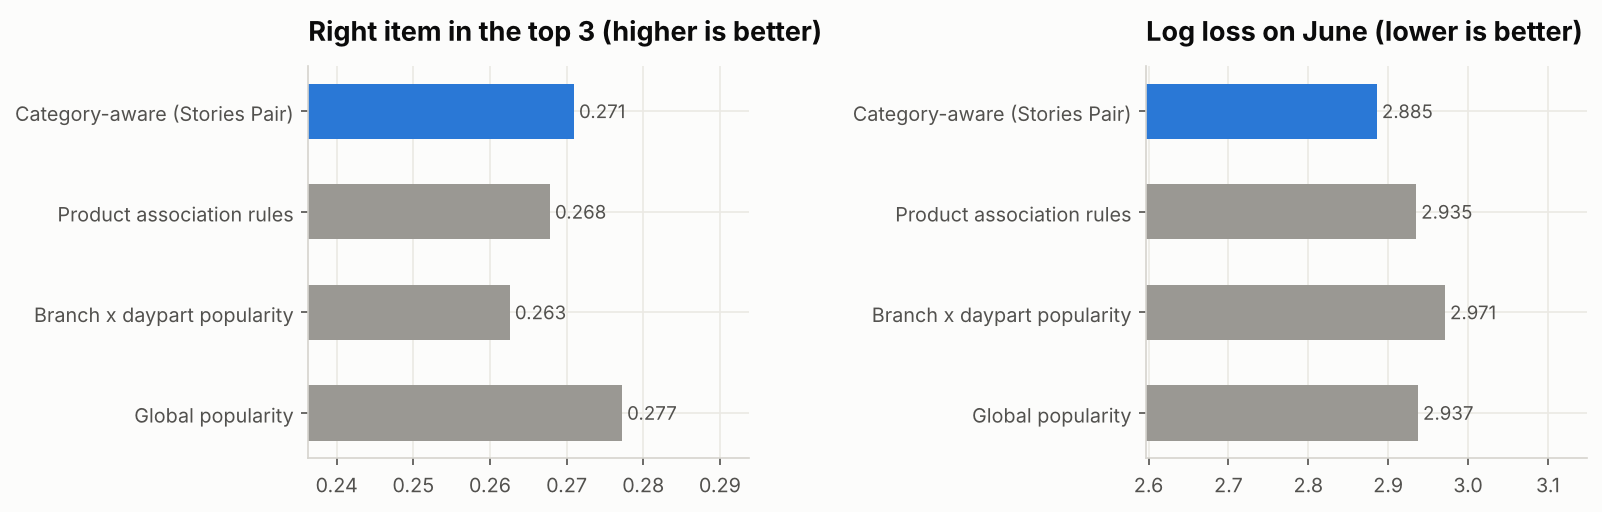

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"wspace": 0.9})
b = bench.set_index("predictor")
for ax, metric, title, better in [(axes[0], "hit@3", "Right item in the top 3", "higher is better"),
                                  (axes[1], "log_loss", "Log loss on June", "lower is better")]:
    cols = [viz.BLUE if "Stories" in i else viz.GREY for i in b.index]
    ax.barh(range(len(b)), b[metric], color=cols, height=0.55)
    ax.set_yticks(range(len(b)), b.index)
    for i, v in enumerate(b[metric]):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=9, color=viz.INK_2)
    ax.set_title(f"{title} ({better})")
    ax.set_xlim(b[metric].min() * 0.9, b[metric].max() * 1.06)
viz.savefig(fig, "02_next_item_benchmark")
plt.show()

Product association rules, the classic market-basket method, are no better than plain popularity on unseen data:
they spread 956 test orders over 506 sparse cells. The category-aware predictor (the structure Stories Pair uses)
gives the best probabilities (lowest log loss). Top-1/top-3 hit rates differ by about one point, within noise for 956
orders. This is why the engine combines the probability with profit rather than suggesting "the most likely item".

In [12]:
viz.savetable(prod, "02_product_pairs")
viz.savetable(cat, "02_category_pairs_among_paired_orders")
viz.savetable(tests, "02_conditional_tests")
_ = viz.savetable(bench, "02_next_item_benchmark")